# IND320 Assignment 3

## Introduction

This is a Jupyter Notebook for the second part of the IND320 - Data to Decision Project Work. This notebook includes:

* Links to Github repository and Streamlit app
* Description of AI Usage
* Downloading and plotting of data from NVE API Magasinstatistikk
* Downloading and plotting of data from the ENTSO-E Transparency Platform API using cassandra and spark

### Video and Links to Github and Streamlit

Github: https://github.com/MagnusFrantsen/IND320-MagnusFrantsen  
Streamlit: https://ind320-magnusfrantsen.streamlit.app/

The video is uploaded to the Github Repository as: "IND320_Project_Work_Part_3.mp4"

### Log Describing Compulsory Work

This section contains a log of the workflow with the Jupyter Notebook and Streamlit App:

I started by reusing the Github Repository and Streamlit app, creating a demo branch to make sure my changes did not affect the feedback for part 1. 

My first step was changing the connection from using the CSV-file to an API connection with the Magasinstatistikk API and converting the response to a pandas dataframe. I then renamed and plotted the same columns as for the first part. 

From the start I decided not include, weeks, years, capacity and next publishing date as I considered these metadata, and it would not make sense to plot these in my opinion. For instance, the capacity of an area would be constant over a period of time and weeks/years would be linear graphs and is difficult to find something to plot against and it making sense.

Then I registered to get a security token at the ENTSO-E API Platform and downloaded two years of cross-border transfer data to and from Norway, from 16-Oct 2024 to 16-Oct 2026 (last two years). Then I created a keyspace in cassandra with a table called crossborder-flow, writing the data to cassandra using spark and extracting the relevant columns (also with spark), and use them to make pie chart and line plots for the NO2-DE connection. Then I inserted the data into MongoDB for use in the Streamlit-app.

Then I started editing the pages according to the features wanted in the assignment, starting by changing the download from reading the CSV-file to API-connection to NVE Magasinstatistikk API, this went smoothly. Then I figured I needed to change the order of some of the filtering making the slider for download/interval and plotting being in the top of the document to only download the wanted time interval. Then I sparred with AI to find a way to group the columns for different area numbers in the same area type. I ended up with the df.groupby() method using a for loop over the area numbers for given area type. 

To not have all lines inside one plot for easier reading of the plots, I decided to give each column each own plot, which also involves its own axis scales and makes it easier to differentiate which line is from which area type/number and column. Therefore I also realised that the normalization used in part 1 of the project was not necessary anymore, and I did not have to differentiate between the change_res_level column and the other columns.

For the table-section using LineChartColumn() I added a more thorough description of what the table is showing. First I decided to plot every area number in the same table, but to make it easier to compare the data from a given point in time I decided it was better to let each area number have each own table.

For the ENTSO-E page I had AI help me create the functions to fetch the secrets and data from MongoDB using get_client() and load_data() function in the flows.py file. Then I downloaded the data creating a pandas dataframe before converting the date column to datetime variable. Then I defined the column and the wanted functionality inside them adding expanders and descriptions where I found it appropriate to place them. Finally I added comments describing what is happening in the code. 

### AI Usage

The AI model used during this assignment Claude Opus 5.5:

Generally, the AI model has suggested code, I have copied and rewritten some of the code. I have tried to use it as little as possible for direct copying of code for the assignment.
The AI model has been used for:

* Breaking down the task description into concrete steps for both the notebook and the Streamlit app
* Set-up of the local Cassandra and the spark connection
* Debugging the requests to NVE Magasinstatistikk and ENTSO-E APIs. The AI model was used to determine how a request should be sent to the ENTSO-E API.
* Write Spark code to insert cross-border flow data into Cassandra and pull out the relevant columns.
* Build pie- and line-chart plots for the crossborder flows
* Connecting to MongoDB from Python and from Streamlit, with credentials stored in Streamlit secrets according to the assignment
* Restructuring the Streamlit-pages and provide documentation for st.radio, st.pills and st.expander

I have personally reviewed, tested, adapted all generated code and added all comments myself, to make sure I understand what the code is actually doing and to get the desired functionality.

# Tasks

## Downloading data from the open-meteo API

In [15]:
# Importing relevant libraries and defining constants for directories to store shapefiles and data.

import time
from pathlib import Path
import pandas as pd
import requests
import geopandas as gpd
import numpy as np
import shapely

# The URL for the Open-Meteo Archive API, which is used to fetch historical weather data.
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Defining the data directory and shapefile directory paths for storing and accessing shapefiles. 
# Including a cache directory for storing weather data to avoid repeated API calls.
DATA_DIR = Path("../data")
SHAPE_DIR = DATA_DIR / "shapefiles"
CACHE_DIR = DATA_DIR / "weather_cache"

In [2]:
# Reading shapefiles for bidding zones and NVE regions using GeoPandas,
# specifying the encoding to handle special characters in the shapefile data.
bidding_zones = gpd.read_file(SHAPE_DIR / "Budområder.shp", encoding="utf-8")
nve_regions = gpd.read_file(SHAPE_DIR / "NVE_Region.shp", encoding="utf-8")

# Performing assertions to ensure that the bidding zones and NVE regions contain the expected values.
assert set(bidding_zones["budomr"]) == {"NO 1", "NO 2", "NO 3", "NO 4", "NO 5"}
assert set(nve_regions["REGION"]) == {"RS", "RØ", "RV", "RM", "RN"}

In [3]:
# Mapping to the VASS areas in Magasinstatistikk.
# The regions are administrative, so their borders only roughly match the VASS areas.
REGION_TO_VASS = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 4}

In [4]:
# Fetch Norway without sea surfaces from NVE
LAND_URL = "https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/11/query"
params = {"where": "OBJTYPE <> 'Havflate'", "outFields": "OBJTYPE", "outSR": 4326, "f": "geojson"}

# Fetching the land area data from the NVE MapServer using a GET request with specified parameters, and converting the response to a GeoDataFrame.
response = requests.get(LAND_URL, params=params, timeout=120)
# Checking the response status to ensure that the request was successful, and raising an error if it was not.
response.raise_for_status()
# Converting the JSON response from the NVE MapServer into a GeoDataFrame
land = gpd.GeoDataFrame.from_features(response.json()["features"], crs=4326)

In [ ]:
# Check the structure of the DataFrame
print(land.head())
# Print the information about the GeoDataFrame
print(land.info())

                                            geometry      OBJTYPE
0  POLYGON ((19.55022 69.86386, 19.59827 69.87243...  ÅpentOmråde
1  POLYGON ((22.9982 69.70829, 23.02399 69.74867,...  ÅpentOmråde
2  POLYGON ((23.37012 69.7102, 23.36667 69.71816,...  ÅpentOmråde
3  POLYGON ((20.86598 69.80516, 20.8638 69.80539,...  ÅpentOmråde
4  POLYGON ((19.6674 69.71362, 19.66323 69.73837,...  ÅpentOmråde
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  1259 non-null   geometry
 1   OBJTYPE   1259 non-null   str     
dtypes: geometry(1), str(1)
memory usage: 31.6 KB
None


In [ ]:
# Printing the numbers of records in land
print(len(land))
# Printing the counts of unique values in the "OBJTYPE" column of the land GeoDataFrame
print(land["OBJTYPE"].value_counts())

1259
OBJTYPE
ÅpentOmråde    756
Skog           429
Innsjø          49
SnøIsbre        25
Name: count, dtype: int64


In [9]:
metric_crs = 25833
samples = 1000
seed = 320

# Creating a function to sample areas from the GeoDataFrame
def sample_areas(areas, land, id_col, rng):

    # Sampling areas from the provided GeoDataFrame based on their intersection with the land area.
    land_union = land.to_crs(metric_crs).geometry.make_valid().union_all()

    # Converting the areas GeoDataFrame to the metric CRS and ensuring that the geometries are valid.
    valid_areas = areas.to_crs(metric_crs).assign(geometry=lambda df: df.geometry.make_valid())

    # Clipping the valid areas to the land union and sampling points from the clipped areas.
    clipped = gpd.clip(valid_areas, land_union, keep_geom_type=True)

    # Sampling points from the clipped areas using the specified random number generator and returning 
    # the sampled points in the WGS 84 coordinate reference system.
    points = clipped.set_index(id_col).sample_points(samples, rng=rng).explode().to_crs(4326)

    # Returning a DataFrame containing the sampled points with their corresponding area identifiers, latitude, and longitude values.
    return pd.DataFrame({"area": points.index, "lat": points.y.values, "lon": points.x.values})

In [10]:
rng = np.random.default_rng(seed)

el_points = sample_areas(bidding_zones, land, "budomr", rng)

el_points["omrType"] = "EL"
el_points["omrnr"] = el_points["area"].str.extract(r"(\d)", expand=False).astype(int)

# Sampling the NVE regions
vass_points = sample_areas(nve_regions, land, "REGION", rng)
vass_points["omrType"] = "VASS"
vass_points["omrnr"] = vass_points["area"].map(REGION_TO_VASS)

# Combining and saving all the points
points = pd.concat([el_points, vass_points], ignore_index=True)

assert (points.groupby("area").size() == samples).all()
assert points["area"].nunique() == 10

## Downloading data from from Open-Meteo

In [12]:
weather_params = [
    "temperature_2m",          # degrees C
    "precipitation",           # mm, sum over the preceding hour
    "snowfall",                # cm of snow, divide by 7 for mm water equivalent
    "shortwave_radiation",     # W/m2, mean over the preceding hour
    "wind_speed_10m",          # m/s, because wind_speed_unit=ms is set below
    "soil_moisture_0_to_7cm",  # m3/m3
]

# Turning 'NO3', 'NO 3' and 'no3' into the same key.
def normalize_region(region):
    return region.replace(" ", "").upper()

grid_deg = 0.25

def load_locations(region, points=points):
    selected = points[points["area"].str.replace(" ", "").str.upper() == normalize_region(region)]

    if selected.empty:
        raise ValueError(f"No points found for area {region!r}")
    
    snapped = selected.assign(
        lat=(selected["lat"] / grid_deg).round() * grid_deg,
        lon=(selected["lon"] / grid_deg).round() * grid_deg,
    )
        # n_points is the number of sampled points in the cell, used as the weight in the mean
    return snapped.groupby(["lat", "lon"]).size().reset_index(name="n_points")

### Response if Limit is Reached

In [13]:
def wait_after_limit(response):
    """Wait out a rate limit. The daily limit has to wait until the next day."""
    reason = response.json().get("reason", "").lower()
    if "daily" in reason:
        raise RuntimeError(f"Daily limit reached. Run again tomorrow: {reason}")
    time.sleep(3600 if "hourly" in reason else 60)

In [14]:
def fetch_location(lat, lon, start_date, end_date, variables=weather_params, max_tries=5):
    """Download hourly data for one location and return a DataFrame."""
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ",".join(variables),
        "models": "era5",
        "timezone": "UTC",
        "wind_speed_unit": "ms",
        "elevation": "nan",  # use the grid cell's own elevation, no downscaling to the point
    }
    for _ in range(max_tries):
        response = requests.get(ARCHIVE_URL, params=params, timeout=120)
        if response.status_code == 429:
            wait_after_limit(response)
            continue
        response.raise_for_status()
        frame = pd.DataFrame(response.json()["hourly"])
        frame["time"] = pd.to_datetime(frame["time"], utc=True)
        return frame
    raise RuntimeError(f"Gave up on location ({lat}, {lon}) after {max_tries} tries")

In [16]:
# Creating a function to download weather data for all locations in a specified region and time interval.
def download_weather(region, start_date, end_date, variables=weather_params, pause=20):
    """Download all locations in an area for a time interval.

    Each location is saved separately, so an interrupted download resumes where it stopped.
    The pause keeps a full year of data below the free limit of 5000 calls per hour.
    """
    locations = load_locations(region)
    cache = CACHE_DIR / f"{normalize_region(region)}_{start_date}_{end_date}"
    cache.mkdir(parents=True, exist_ok=True)
    print(f"{region}: {len(locations)} ERA5 grid cells")

    frames = []
    for number, row in enumerate(locations.itertuples(), start=1):
        path = cache / f"{row.lat}_{row.lon}.csv"
        if path.exists():
            frame = pd.read_csv(path, parse_dates=["time"])
        else:
            frame = fetch_location(row.lat, row.lon, start_date, end_date, variables)
            frame.to_csv(path, index=False)
            print(f"{number}/{len(locations)} done")
            time.sleep(pause)
        frames.append(frame.assign(lat=row.lat, lon=row.lon, n_points=row.n_points))
    return pd.concat(frames, ignore_index=True)


def region_mean(weather, variables=weather_params):
    """Compute the hourly mean for the area, weighted by the number of points per cell."""
    values = weather[variables]
    weighted_sum = values.mul(weather["n_points"], axis=0).groupby(weather["time"]).sum()
    weight_sum = values.notna().mul(weather["n_points"], axis=0).groupby(weather["time"]).sum()
    return weighted_sum / weight_sum

In [17]:
test_location = load_locations("NO3").iloc[0]
test_frame = fetch_location(test_location["lat"], test_location["lon"], "2024-01-01", "2024-01-02")
test_frame.describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,48.0,1.652083,1.603585,-1.30,0.775,1.500,2.825,4.60
precipitation,48.0,0.012500,0.033422,0.00,0.000,0.000,0.000,0.10
snowfall,48.0,0.005833,0.019552,0.00,0.000,0.000,0.000,0.07
shortwave_radiation,48.0,4.958333,11.232473,0.00,0.000,0.000,0.250,47.00
wind_speed_10m,48.0,11.024375,1.172551,8.78,9.970,11.025,12.115,12.84
soil_moisture_0_to_7cm,48.0,0.000000,0.000000,0.00,0.000,0.000,0.000,0.00


In [18]:
no3_2024 = download_weather("NO3", "2024-01-01", "2024-12-31")
no3_mean = region_mean(no3_2024)
no3_mean.to_csv(DATA_DIR / "NO3_2024_hourly.csv")
no3_mean.describe().T

NO3: 230 ERA5 grid cells
1/230 done
2/230 done
3/230 done
4/230 done
5/230 done
6/230 done
7/230 done
8/230 done
9/230 done
10/230 done
11/230 done
12/230 done
13/230 done
14/230 done
15/230 done
16/230 done
17/230 done
18/230 done
19/230 done
20/230 done
21/230 done
22/230 done
23/230 done
24/230 done
25/230 done
26/230 done
27/230 done
28/230 done
29/230 done
30/230 done
31/230 done
32/230 done
33/230 done
34/230 done
35/230 done
36/230 done
37/230 done
38/230 done
39/230 done
40/230 done
41/230 done
42/230 done
43/230 done
44/230 done
45/230 done
46/230 done
47/230 done
48/230 done
49/230 done
50/230 done
51/230 done
52/230 done
53/230 done
54/230 done
55/230 done
56/230 done
57/230 done
58/230 done
59/230 done
60/230 done
61/230 done
62/230 done
63/230 done
64/230 done
65/230 done
66/230 done
67/230 done
68/230 done
69/230 done
70/230 done
71/230 done
72/230 done
73/230 done
74/230 done
75/230 done
76/230 done
77/230 done
78/230 done
79/230 done
80/230 done
81/230 done
82/230 done


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8784.0,4.563771,7.619016,-16.300400,-0.462900,4.147150,10.348425,24.524000
precipitation,8784.0,0.199195,0.285345,0.000000,0.010100,0.085600,0.278225,3.341900
snowfall,8784.0,0.042961,0.102257,0.000000,0.000000,0.000280,0.034650,1.842120
shortwave_radiation,8784.0,100.039489,158.632280,0.000000,0.000000,4.324500,152.714750,753.959000
wind_speed_10m,8784.0,2.845192,1.120053,0.792910,2.018685,2.610590,3.476030,9.105240
soil_moisture_0_to_7cm,8784.0,0.292289,0.031053,0.160538,0.276093,0.293861,0.313749,0.364479


### Outliers and anomalies

#### Plotting the average precipitation as a function of time

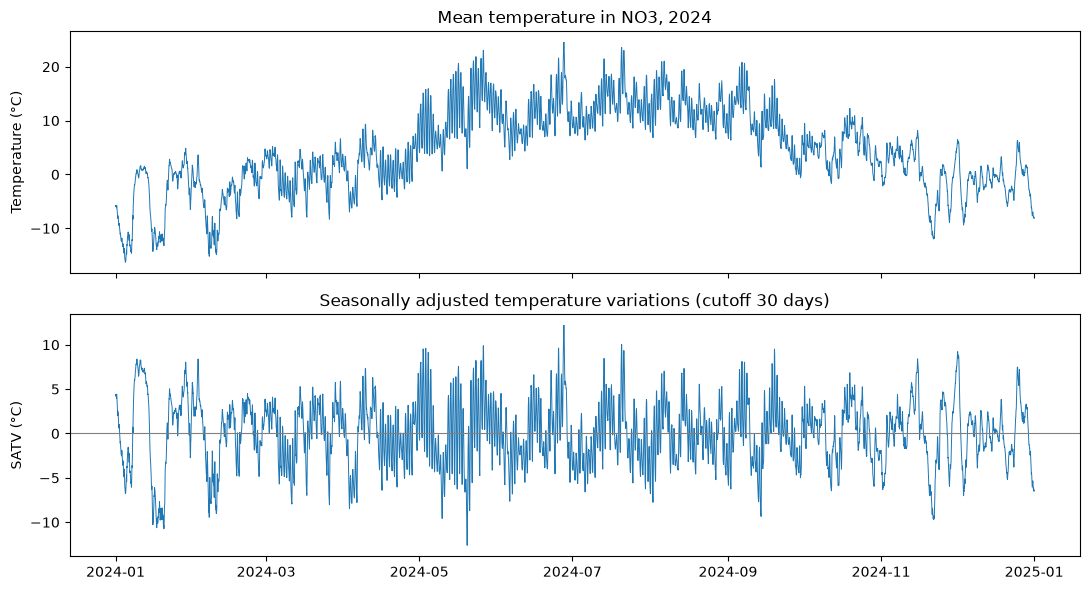

In [20]:
import matplotlib.pyplot as plt
from scipy.fft import dct, idct

# Creating a function to remove slow variations from a time series using the Discrete Cosine Transform (DCT).
def dct_highpass(series, cutoff_days=30):
    """Remove variation slower than cutoff_days using the Discrete Cosine Transform."""
    if series.isna().any():
        raise ValueError("The DCT needs a series without missing values")

    # The length of the series is determined, and the DCT coefficients are computed using the 'ortho' normalization.
    n = len(series)
    coefficients = dct(series.to_numpy(), norm="ortho")

    # Coefficient k has a period of 2n / k hours, so slower waves have a lower k
    cutoff = round(2 * n / (cutoff_days * 24))
    coefficients[:cutoff] = 0

    # Returning the inverse DCT of the modified coefficients, which represents 
    # the seasonally adjusted temperature variations (SATV) with a cutoff of 30 days.
    return pd.Series(idct(coefficients, norm="ortho"), index=series.index, name="satv")

# Computing the seasonally adjusted temperature variations (SATV) for the mean temperature in NO3 using the DCT highpass filter with a cutoff of 30 days.
satv = dct_highpass(no3_mean["temperature_2m"])

# Using two panels, because the two series have different baselines
fig, (ax_mean, ax_satv) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Plotting the mean temperature in NO3 for 2024 on the first panel, with a line width of 0.7, and setting the y-axis label and title.
ax_mean.plot(no3_mean.index, no3_mean["temperature_2m"], linewidth=0.7)
ax_mean.set_ylabel("Temperature (°C)")
ax_mean.set_title("Mean temperature in NO3, 2024")

# Plotting the seasonally adjusted temperature variations (SATV) on the second panel, 
# with a line width of 0.7, adding a horizontal line at y=0 for reference, and setting the y-axis label and title.
ax_satv.plot(satv.index, satv, linewidth=0.7)
ax_satv.axhline(0, color="gray", linewidth=0.8)
ax_satv.set_ylabel("SATV (°C)")
ax_satv.set_title("Seasonally adjusted temperature variations (cutoff 30 days)")

# Adjusting the layout of the plots to prevent overlap and ensure that the labels and titles are clearly visible, and displaying the plots.
plt.tight_layout()
# Displaying the plots using plt.show()
plt.show()